In [1]:
# loading modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import colorcet as cc

# Loading the data

In [2]:
# loading dhe data
Brain_mammals = pd.read_csv("/content/mammals_with_feature_engineering_17_09_2024.csv")
# Brain = Brain.drop(['Unnamed: 0'], axis=1)
# Drop the row with index 91 from the mammalian dataset
Brain_mammals = Brain_mammals.drop(index=91)

# Display the rows around the dropped index to verify
display(Brain_mammals.tail(5))
# Brain_mammals.head(100)

,Unnamed: 0,Animal,Order,Family,Forebrain m,Cerebellum m,Whole brain m,Forebrain n,Cerebellum n,Whole brain n,...,Whole brain n d,Forebrain m per body m,Cerebellum m per body m,Whole brain m per body m,Forebrain n per body m,Cerebellum n per body m,Whole brain n per body m,Forebrain m/Rest m,Cerebellum m/Rest m,Forebrain m/Cerebellum m
87,87,Harbour porpoise,Artiodactyla,Phocoenidae,382.770,106.140,563.530,2.770000e+09,2.340000e+10,2.630000e+10,...,46670.097422,0.729086,0.202171,1.073390,52761.904762,4.457143e+05,5.009524e+05,5.129590,1.422407,3.606275
88,88,Yellow baboon,Primates,Cercopithecidae,120.214,13.745,151.194,2.875000e+09,7.794000e+09,1.094800e+10,...,72410.280831,0.601070,0.068725,0.755970,143750.000000,3.897000e+05,5.474000e+05,6.974993,0.797505,8.746017
89,89,Common minke whale,Artiodactyla,Balaenopteridae,2037.024,415.918,2715.900,3.134000e+09,5.421600e+10,5.747200e+10,...,21161.309327,0.027160,0.005546,0.036212,417.866667,7.228800e+03,7.662933e+03,7.746575,1.581690,4.897658
90,90,African elephant,Proboscidea,Elephantidae,2847.000,1171.000,4618.000,5.593000e+09,2.507000e+11,2.570400e+11,...,55660.459073,0.059312,0.024396,0.096208,1165.208333,5.222917e+04,5.355000e+04,4.745000,1.951667,2.431255
92,92,Human,Primates,Hominidae,1232.000,154.020,1508.000,1.634000e+10,6.903000e+10,8.606000e+10,...,57068.965517,1.985976,0.248279,2.430886,263399.693721,1.112759e+06,1.387281e+06,10.100016,1.262666,7.998961


In [3]:
Brain_birds = pd.read_csv("/content/birds_with_feature_engineering_17_09_2024.csv")
# Brain = Brain.drop(['Unnamed: 0'], axis=1)
Brain_birds.head(8)

,Unnamed: 0,Animal,Order,Family,Forebrain m,Cerebellum m,Whole brain m,Forebrain n,Cerebellum n,Whole brain n,...,Cerebellum n r %,Forebrain n d,Cerebellum n d,Whole brain n d,Forebrain m per body m,Cerebellum m per body m,Whole brain m per body m,Forebrain n per body m,Cerebellum n per body m,Whole brain n per body m
0,0,Namaqua dove,Columbiformes,Columbidae,0.240,0.0870,0.555,14167000.0,59533000.0,94490000.0,...,63.004551,59029.166667,684287.356322,170252.252252,0.753532,0.273155,1.742543,444803.767661,1.869168e+06,2.966719e+06
1,1,Common ground dove,Columbiformes,Columbidae,0.246,0.0750,0.572,17602000.0,51380000.0,89630000.0,...,57.324557,71552.845528,685066.666667,156695.804196,0.697338,0.212603,1.621453,498965.331519,1.456473e+06,2.540749e+06
2,2,Diamond dove,Columbiformes,Columbidae,0.240,0.0776,0.545,18209000.0,54101000.0,87879000.0,...,61.563058,75870.833333,697177.835052,161245.871560,0.601052,0.194340,1.364889,456023.040321,1.354896e+06,2.200826e+06
3,3,King quail,Galliformes,Phasianidae,0.220,0.0717,0.521,20523000.0,42945000.0,80478000.0,...,53.362410,93286.363636,598953.974895,154468.330134,0.502168,0.163661,1.189226,468454.690710,9.802556e+05,1.836978e+06
4,4,Common quail,Galliformes,Phasianidae,0.360,0.1090,0.787,22568000.0,75198000.0,117760000.0,...,63.856997,62688.888889,689889.908257,149631.512071,0.379507,0.114906,0.829644,237908.496732,7.927261e+05,1.241408e+06
5,5,Common emerald dove,Columbiformes,Columbidae,0.494,0.1760,1.126,27148000.0,109818000.0,168489000.0,...,65.178142,54955.465587,623965.909091,149634.991119,0.412905,0.147108,0.941157,226914.075560,9.179037e+05,1.408300e+06
6,6,Common bronzewing,Columbiformes,Columbidae,0.869,0.2570,1.848,34077000.0,145208000.0,216703000.0,...,67.007840,39214.039125,565011.673152,117263.528139,0.283964,0.083980,0.603872,111353.647578,4.744972e+05,7.081219e+05
7,7,Pink-necked green pigeon,Columbiformes,Columbidae,0.645,0.2000,1.339,34357000.0,114792000.0,174476000.0,...,65.792430,53266.666667,573960.000000,130303.211352,0.500582,0.155219,1.039193,266643.383780,8.908964e+05,1.354102e+06


# Functions which will fit the forebrain data by power function for each animal order and also display average brain structure mass relative to entire brain mass

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

def power_regression(x, y):
    """Fits power regression y = a * x^b and returns coefficients."""
    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)

    # Filter positive values (log requires >0)
    mask = (x > 0) & (y > 0)
    x, y = x[mask], y[mask]

    if len(x) < 2:  # not enough points
        return None, None, None

    log_x = np.log(x)
    log_y = np.log(y)

    slope, intercept, r_value, _, _ = linregress(log_x, log_y)
    a = np.exp(intercept)
    b = slope
    r2 = r_value**2

    return a, b, r2

def analyze_orders_forebrain(df, plot=True):
    results = {}

    for order, group in df.groupby("Order"):
        x = group["Forebrain m"].values
        y = group["Forebrain n"].values
        relative_x = group["Forebrain m r %"].values
        relative_x_mean = np.mean(relative_x)

        a, b, r2 = power_regression(x, y)
        if a is None:
            continue

        formula = f"y = {a:.4f} * x^{b:.4f}"
        results[order] = {"a": a, "b": b, "R²": r2, "formula": formula}

        print(f"Order: {order}")
        print(f"  Formula: {formula}")
        print(f"  R² = {r2:.4f}\n")
        print(f"  Relative x mean: {relative_x_mean:.4f}\n")

        if plot:
            # Plot each order separately
            plt.scatter(np.log10(x), np.log10(y), label=f"{order} data")
            x_fit = np.linspace(min(x), max(x), 200)
            y_fit = a * x_fit**b
            plt.plot(np.log10(x_fit), np.log10(y_fit), label=f"{order} fit")

    if plot:
        plt.xlabel("log 10 Forebrain mass (m)")
        plt.ylabel("log 10 Forebrain neurons (n)")
        plt.title("Power Regression by Order")
        plt.legend()
        plt.grid(True)
        plt.show()

    return results


# Example usage (replace with your CSV file)
# df = pd.read_csv("brain_dataset.csv")
# results = analyze_orders(df, plot=True)


# Mammalian forebrain results

In [8]:
sns.set("paper", rc={"figure.figsize": (12, 8)})

Order: Artiodactyla
  Formula: y = 25841580.7551 * x^0.6744
  R² = 0.8744

  Relative x mean: 69.9395

Order: Carnivora
  Formula: y = 44757957.9565 * x^0.5892
  R² = 0.5759

  Relative x mean: 64.3833

Order: Chiroptera
  Formula: y = 22423615.3228 * x^0.5689
  R² = 0.8938

  Relative x mean: 47.1977

Order: Didelphimorphia
  Formula: y = 26518118.4030 * x^0.4311
  R² = 0.7009

  Relative x mean: 48.0015

Order: Diprotodontia
  Formula: y = 32790939.0873 * x^0.6826
  R² = 0.8824

  Relative x mean: 59.8880

Order: Eulipotyphla
  Formula: y = 27598022.5770 * x^0.4505
  R² = 0.7504

  Relative x mean: 52.2076

Order: Hyracoidea
  Formula: y = 1348098.3314 * x^2.1237
  R² = 1.0000

  Relative x mean: 60.6177

Order: Macroscelidea
  Formula: y = 31962168.0818 * x^0.2811
  R² = 1.0000

  Relative x mean: 48.0336

Order: Primates
  Formula: y = 45113244.8647 * x^0.8762
  R² = 0.9560

  Relative x mean: 72.0883

Order: Rodentia
  Formula: y = 32156372.2231 * x^0.6095
  R² = 0.9223

  Relativ

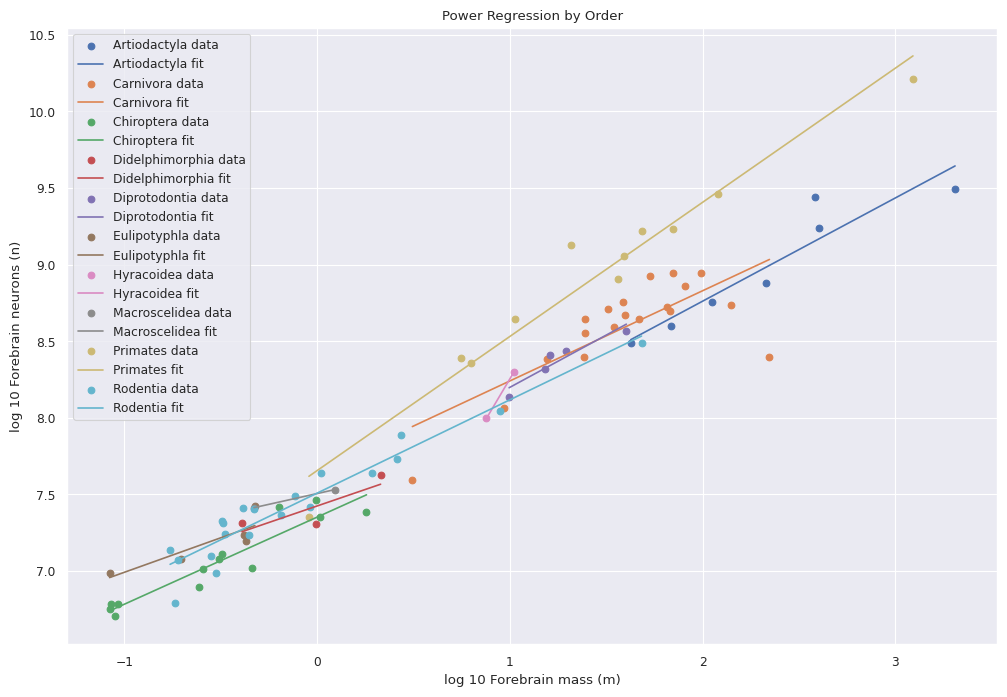

{'Artiodactyla': {'a': np.float64(25841580.75506636),
  'b': np.float64(0.6743800266723984),
  'R²': np.float64(0.8743606245168691),
  'formula': 'y = 25841580.7551 * x^0.6744'},
 'Carnivora': {'a': np.float64(44757957.956457734),
  'b': np.float64(0.5891770573598835),
  'R²': np.float64(0.5759188425343912),
  'formula': 'y = 44757957.9565 * x^0.5892'},
 'Chiroptera': {'a': np.float64(22423615.32278272),
  'b': np.float64(0.5688920655706657),
  'R²': np.float64(0.8938356804013977),
  'formula': 'y = 22423615.3228 * x^0.5689'},
 'Didelphimorphia': {'a': np.float64(26518118.403025582),
  'b': np.float64(0.431143317347922),
  'R²': np.float64(0.7009106386943257),
  'formula': 'y = 26518118.4030 * x^0.4311'},
 'Diprotodontia': {'a': np.float64(32790939.08732061),
  'b': np.float64(0.682565733414059),
  'R²': np.float64(0.8823860184585658),
  'formula': 'y = 32790939.0873 * x^0.6826'},
 'Eulipotyphla': {'a': np.float64(27598022.57699768),
  'b': np.float64(0.4505040490435971),
  'R²': np.fl

In [9]:
analyze_orders_forebrain(Brain_mammals, plot=True)

# Bird forebrain results

Order: Accipitriformes
  Formula: y = 84062472.7396 * x^0.7602
  R² = 0.7779

  Relative x mean: 55.4040

Order: Anseriformes
  Formula: y = 83280515.0267 * x^0.6325
  R² = 0.6008

  Relative x mean: 59.4711

Order: Bucerotiformes
  Formula: y = 153970642.5073 * x^0.9124
  R² = 0.9971

  Relative x mean: 62.4347

Order: Columbiformes
  Formula: y = 52448144.9371 * x^0.7381
  R² = 0.8093

  Relative x mean: 46.1190

Order: Coraciiformes
  Formula: y = 64468305.7835 * x^0.9628
  R² = 1.0000

  Relative x mean: 54.8144

Order: Falconiformes
  Formula: y = 146979880.7691 * x^0.7725
  R² = 0.9989

  Relative x mean: 56.5011

Order: Galliformes
  Formula: y = 54339583.5254 * x^0.6427
  R² = 0.8737

  Relative x mean: 47.8764

Order: Passeriformes
  Formula: y = 169728573.7499 * x^0.8495
  R² = 0.9357

  Relative x mean: 62.3328

Order: Piciformes
  Formula: y = 154508183.7458 * x^0.8104
  R² = 0.9413

  Relative x mean: 54.3325

Order: Psittaciformes
  Formula: y = 176886534.3693 * x^0.8911


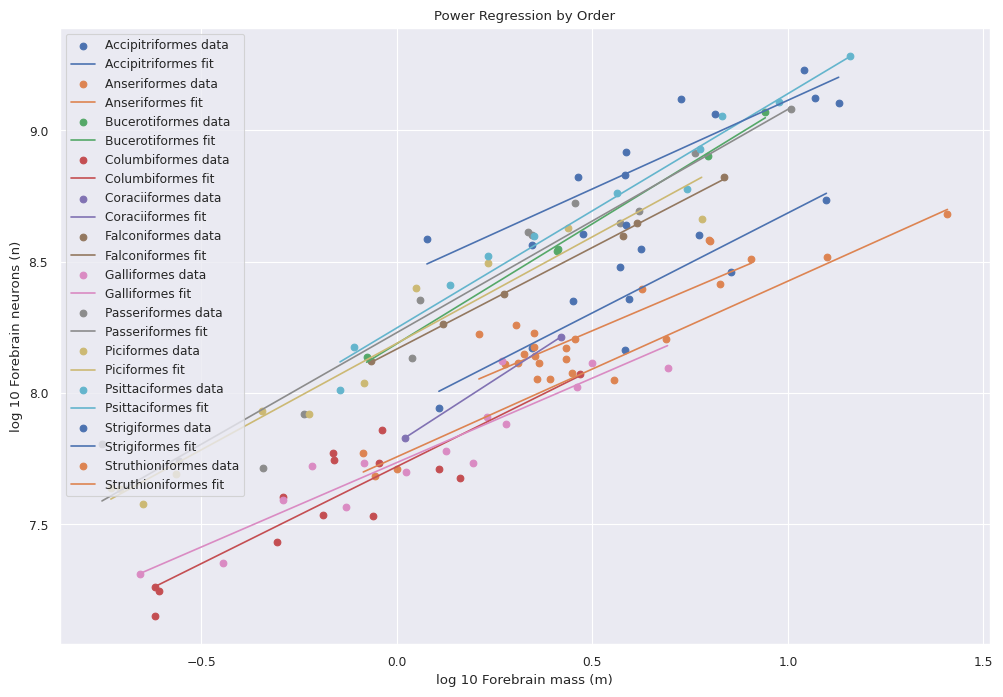

{'Accipitriformes': {'a': np.float64(84062472.7395952),
  'b': np.float64(0.760192290780315),
  'R²': np.float64(0.7778991925577513),
  'formula': 'y = 84062472.7396 * x^0.7602'},
 'Anseriformes': {'a': np.float64(83280515.02668528),
  'b': np.float64(0.6324866296997458),
  'R²': np.float64(0.6008367962173996),
  'formula': 'y = 83280515.0267 * x^0.6325'},
 'Bucerotiformes': {'a': np.float64(153970642.50726023),
  'b': np.float64(0.9124133443714704),
  'R²': np.float64(0.9971359871388266),
  'formula': 'y = 153970642.5073 * x^0.9124'},
 'Columbiformes': {'a': np.float64(52448144.93708316),
  'b': np.float64(0.7380670504695843),
  'R²': np.float64(0.8092902861435216),
  'formula': 'y = 52448144.9371 * x^0.7381'},
 'Coraciiformes': {'a': np.float64(64468305.78345359),
  'b': np.float64(0.9628083642648613),
  'R²': np.float64(1.0),
  'formula': 'y = 64468305.7835 * x^0.9628'},
 'Falconiformes': {'a': np.float64(146979880.76909313),
  'b': np.float64(0.7725021026591249),
  'R²': np.float64

In [10]:
analyze_orders_forebrain(Brain_birds, plot=True)

# Function which applies power regression to cerebellum data and also calculates relative structure mass for each order

In [11]:
def analyze_orders_cerebellum(df, plot=True):
    results = {}

    for order, group in df.groupby("Order"):
        x = group["Cerebellum m"].values
        y = group["Cerebellum n"].values
        relative_x = group["Cerebellum m r %"].values
        relative_x_mean = np.mean(relative_x)

        a, b, r2 = power_regression(x, y)
        if a is None:
            continue

        formula = f"y = {a:.4f} * x^{b:.4f}"
        results[order] = {"a": a, "b": b, "R²": r2, "formula": formula}

        print(f"Order: {order}")
        print(f"  Formula: {formula}")
        print(f"  R² = {r2:.4f}\n")
        print(f"  Relative x mean: {relative_x_mean:.4f}\n")

        if plot:
            # Plot each order separately
            plt.scatter(np.log10(x), np.log10(y), label=f"{order} data")
            x_fit = np.linspace(min(x), max(x), 200)
            y_fit = a * x_fit**b
            plt.plot(np.log10(x_fit), np.log10(y_fit), label=f"{order} fit")

    if plot:
        plt.xlabel("log 10 Cerebellum mass (m)")
        plt.ylabel("log 10 Cerebellum neurons (n)")
        plt.title("Power Regression by Order")
        plt.legend()
        plt.grid(True)
        plt.show()

    return results

# Mammalian cerebellum results

Order: Artiodactyla
  Formula: y = 238961293.1067 * x^0.9042
  R² = 0.9713

  Relative x mean: 12.7486

Order: Carnivora
  Formula: y = 351326955.6980 * x^0.8482
  R² = 0.9079

  Relative x mean: 11.3281

Order: Chiroptera
  Formula: y = 408043087.8621 * x^0.7968
  R² = 0.9407

  Relative x mean: 17.3163

Order: Didelphimorphia
  Formula: y = 392037406.7988 * x^0.8809
  R² = 0.9759

  Relative x mean: 17.5071

Order: Diprotodontia
  Formula: y = 349599548.8066 * x^0.8592
  R² = 0.9953

  Relative x mean: 12.7745

Order: Eulipotyphla
  Formula: y = 831983458.1230 * x^0.9536
  R² = 0.9802

  Relative x mean: 13.5975

Order: Hyracoidea
  Formula: y = 22048613.3319 * x^4.2922
  R² = 1.0000

  Relative x mean: 13.5979

Order: Macroscelidea
  Formula: y = 170120365.7803 * x^0.3612
  R² = 1.0000

  Relative x mean: 14.3064

Order: Primates
  Formula: y = 536210600.3490 * x^0.9621
  R² = 0.9888

  Relative x mean: 11.5127

Order: Rodentia
  Formula: y = 332254541.7746 * x^0.7866
  R² = 0.9370


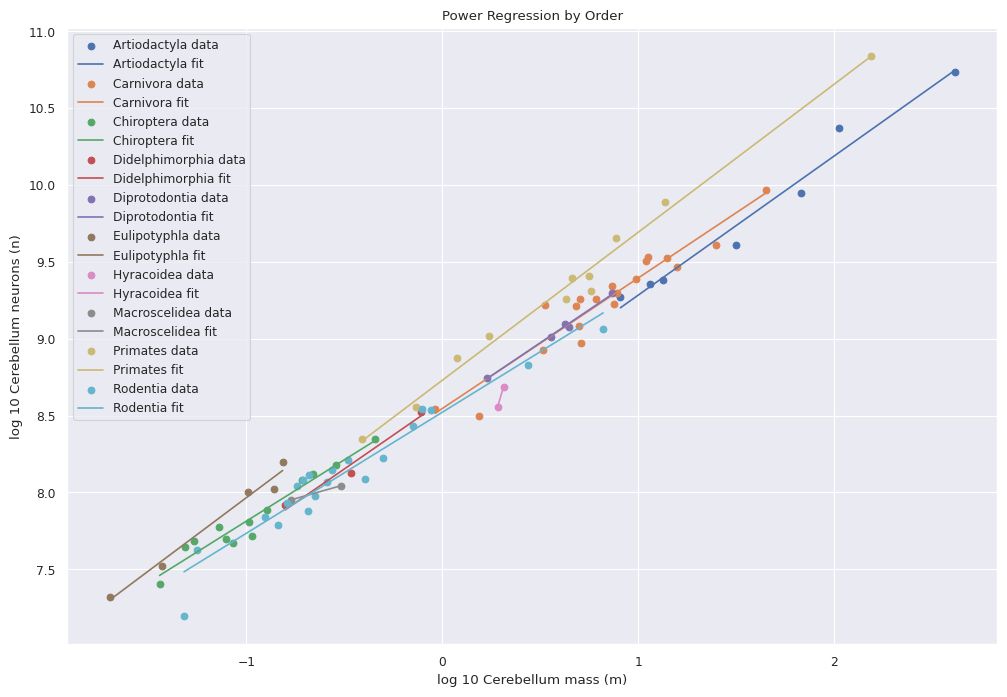

{'Artiodactyla': {'a': np.float64(238961293.10666874),
  'b': np.float64(0.9041814035561737),
  'R²': np.float64(0.9713247883387225),
  'formula': 'y = 238961293.1067 * x^0.9042'},
 'Carnivora': {'a': np.float64(351326955.6979748),
  'b': np.float64(0.8481984932124146),
  'R²': np.float64(0.9079499006249312),
  'formula': 'y = 351326955.6980 * x^0.8482'},
 'Chiroptera': {'a': np.float64(408043087.86210114),
  'b': np.float64(0.7968125455697592),
  'R²': np.float64(0.9407045894441216),
  'formula': 'y = 408043087.8621 * x^0.7968'},
 'Didelphimorphia': {'a': np.float64(392037406.7988178),
  'b': np.float64(0.8809214555171672),
  'R²': np.float64(0.9759158651912649),
  'formula': 'y = 392037406.7988 * x^0.8809'},
 'Diprotodontia': {'a': np.float64(349599548.8066498),
  'b': np.float64(0.8592305393938914),
  'R²': np.float64(0.9952659555445567),
  'formula': 'y = 349599548.8066 * x^0.8592'},
 'Eulipotyphla': {'a': np.float64(831983458.1230388),
  'b': np.float64(0.9535667097424052),
  'R²'

In [12]:
analyze_orders_cerebellum(Brain_mammals, plot=True)

# Bird cerebellum results

Order: Accipitriformes
  Formula: y = 459489103.9660 * x^0.7635
  R² = 0.9564

  Relative x mean: 14.0371

Order: Anseriformes
  Formula: y = 338334131.1300 * x^0.7891
  R² = 0.7883

  Relative x mean: 12.7949

Order: Bucerotiformes
  Formula: y = 578038030.5471 * x^0.8205
  R² = 0.9744

  Relative x mean: 10.0092

Order: Columbiformes
  Formula: y = 423349609.8989 * x^0.8138
  R² = 0.9765

  Relative x mean: 14.6996

Order: Coraciiformes
  Formula: y = 390076746.5369 * x^0.6672
  R² = 1.0000

  Relative x mean: 11.9800

Order: Falconiformes
  Formula: y = 539911160.4798 * x^0.7949
  R² = 0.9985

  Relative x mean: 13.8536

Order: Galliformes
  Formula: y = 380141600.0772 * x^0.8121
  R² = 0.9451

  Relative x mean: 13.4039

Order: Passeriformes
  Formula: y = 725247592.8178 * x^0.8217
  R² = 0.9717

  Relative x mean: 9.5322

Order: Piciformes
  Formula: y = 623275534.8521 * x^0.8415
  R² = 0.9824

  Relative x mean: 13.7531

Order: Psittaciformes
  Formula: y = 593665133.3214 * x^0.8

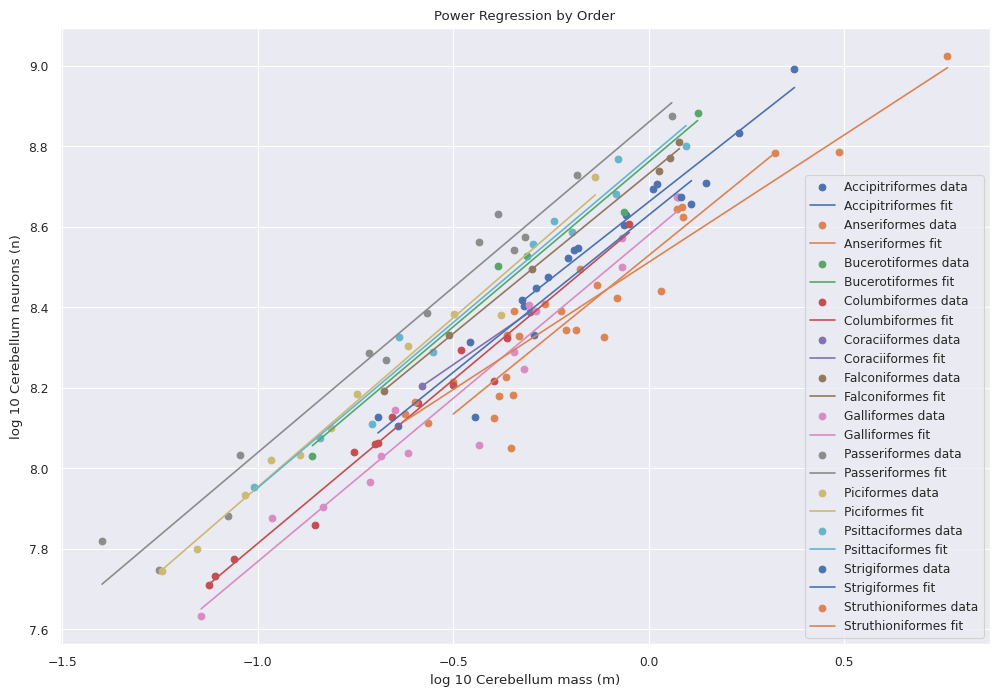

{'Accipitriformes': {'a': np.float64(459489103.9660269),
  'b': np.float64(0.7634696111642129),
  'R²': np.float64(0.9563602126767388),
  'formula': 'y = 459489103.9660 * x^0.7635'},
 'Anseriformes': {'a': np.float64(338334131.130011),
  'b': np.float64(0.7891306680682998),
  'R²': np.float64(0.7883344864568904),
  'formula': 'y = 338334131.1300 * x^0.7891'},
 'Bucerotiformes': {'a': np.float64(578038030.5471408),
  'b': np.float64(0.8205214203572426),
  'R²': np.float64(0.9743852007837246),
  'formula': 'y = 578038030.5471 * x^0.8205'},
 'Columbiformes': {'a': np.float64(423349609.89889705),
  'b': np.float64(0.8137996732251177),
  'R²': np.float64(0.9764908788533633),
  'formula': 'y = 423349609.8989 * x^0.8138'},
 'Coraciiformes': {'a': np.float64(390076746.5369092),
  'b': np.float64(0.6671955380449598),
  'R²': np.float64(0.9999999999999996),
  'formula': 'y = 390076746.5369 * x^0.6672'},
 'Falconiformes': {'a': np.float64(539911160.4797506),
  'b': np.float64(0.7948500571252967),

In [13]:
analyze_orders_cerebellum(Brain_birds, plot=True)

# Predictions for Short-finned pilot whale

In [14]:
import pandas as pd
import numpy as np

def calculate_neuron_predictions(mass_g=1800):
    # Re-run regressions to ensure we have the coefficients programmatically
    datasets = {
        "Mammals": Brain_mammals,
        "Birds": Brain_birds
    }

    print(f"--- Forebrain Neuron Count Predictions for a {mass_g}g Forebrain ---\n")

    for group_name, df in datasets.items():
        print(f"== {group_name} ==")
        for order, group in df.groupby("Order"):
            x = group["Forebrain m"].values
            y = group["Forebrain n"].values

            # Filter positive values for log transformation
            mask = (x > 0) & (y > 0)
            x_clean, y_clean = x[mask], y[mask]

            if len(x_clean) < 2:
                continue

            log_x = np.log(x_clean)
            log_y = np.log(y_clean)

            slope, intercept = np.polyfit(log_x, log_y, 1)
            a = np.exp(intercept)
            b = slope

            # Apply formula: y = a * x^b
            # Mass must be in the same units as the training data (grams/milligrams as represented in 'Forebrain m')
            predicted_neurons = a * (mass_g ** b)
            print(f"  Order: {order:<18} | Prediction: {predicted_neurons:,.0f} neurons (Formula: y = {a:.2e} * x^{b:.3f})")
        print()

calculate_neuron_predictions(1800)

--- Forebrain Neuron Count Predictions for a 1800g Forebrain ---

== Mammals ==
  Order: Artiodactyla       | Prediction: 4,051,443,952 neurons (Formula: y = 2.58e+07 * x^0.674)
  Order: Carnivora          | Prediction: 3,705,118,815 neurons (Formula: y = 4.48e+07 * x^0.589)
  Order: Chiroptera         | Prediction: 1,594,425,876 neurons (Formula: y = 2.24e+07 * x^0.569)
  Order: Didelphimorphia    | Prediction: 671,477,851 neurons (Formula: y = 2.65e+07 * x^0.431)
  Order: Diprotodontia      | Prediction: 5,466,273,021 neurons (Formula: y = 3.28e+07 * x^0.683)
  Order: Eulipotyphla       | Prediction: 807,962,882 neurons (Formula: y = 2.76e+07 * x^0.451)
  Order: Hyracoidea         | Prediction: 11,041,371,069,758 neurons (Formula: y = 1.35e+06 * x^2.124)
  Order: Macroscelidea      | Prediction: 262,900,943 neurons (Formula: y = 3.20e+07 * x^0.281)
  Order: Primates           | Prediction: 32,109,823,678 neurons (Formula: y = 4.51e+07 * x^0.876)
  Order: Rodentia           | Predicti

# Predictions for Long-finned pilot whale

In [15]:
calculate_neuron_predictions(2700)

--- Forebrain Neuron Count Predictions for a 2700g Forebrain ---

== Mammals ==
  Order: Artiodactyla       | Prediction: 5,325,522,981 neurons (Formula: y = 2.58e+07 * x^0.674)
  Order: Carnivora          | Prediction: 4,704,907,281 neurons (Formula: y = 4.48e+07 * x^0.589)
  Order: Chiroptera         | Prediction: 2,008,081,125 neurons (Formula: y = 2.24e+07 * x^0.569)
  Order: Didelphimorphia    | Prediction: 799,746,341 neurons (Formula: y = 2.65e+07 * x^0.431)
  Order: Diprotodontia      | Prediction: 7,209,168,539 neurons (Formula: y = 3.28e+07 * x^0.683)
  Order: Eulipotyphla       | Prediction: 969,887,216 neurons (Formula: y = 2.76e+07 * x^0.451)
  Order: Hyracoidea         | Prediction: 26,121,150,263,820 neurons (Formula: y = 1.35e+06 * x^2.124)
  Order: Macroscelidea      | Prediction: 294,643,417 neurons (Formula: y = 3.20e+07 * x^0.281)
  Order: Primates           | Prediction: 45,807,073,707 neurons (Formula: y = 4.51e+07 * x^0.876)
  Order: Rodentia           | Predicti

# Predictions for Humpback whale

In [16]:
calculate_neuron_predictions(4500)

--- Forebrain Neuron Count Predictions for a 4500g Forebrain ---

== Mammals ==
  Order: Artiodactyla       | Prediction: 7,515,755,249 neurons (Formula: y = 2.58e+07 * x^0.674)
  Order: Carnivora          | Prediction: 6,357,103,215 neurons (Formula: y = 4.48e+07 * x^0.589)
  Order: Chiroptera         | Prediction: 2,685,277,961 neurons (Formula: y = 2.24e+07 * x^0.569)
  Order: Didelphimorphia    | Prediction: 996,783,562 neurons (Formula: y = 2.65e+07 * x^0.431)
  Order: Diprotodontia      | Prediction: 10,216,720,988 neurons (Formula: y = 3.28e+07 * x^0.683)
  Order: Eulipotyphla       | Prediction: 1,220,857,555 neurons (Formula: y = 2.76e+07 * x^0.451)
  Order: Hyracoidea         | Prediction: 77,292,594,502,216 neurons (Formula: y = 1.35e+06 * x^2.124)
  Order: Macroscelidea      | Prediction: 340,145,837 neurons (Formula: y = 3.20e+07 * x^0.281)
  Order: Primates           | Prediction: 71,667,258,319 neurons (Formula: y = 4.51e+07 * x^0.876)
  Order: Rodentia           | Predi

# Predictions for Sperm whale

In [17]:
calculate_neuron_predictions(7000)

--- Forebrain Neuron Count Predictions for a 7000g Forebrain ---

== Mammals ==
  Order: Artiodactyla       | Prediction: 10,124,565,518 neurons (Formula: y = 2.58e+07 * x^0.674)
  Order: Carnivora          | Prediction: 8,247,338,359 neurons (Formula: y = 4.48e+07 * x^0.589)
  Order: Chiroptera         | Prediction: 3,452,640,820 neurons (Formula: y = 2.24e+07 * x^0.569)
  Order: Didelphimorphia    | Prediction: 1,205,954,798 neurons (Formula: y = 2.65e+07 * x^0.431)
  Order: Diprotodontia      | Prediction: 13,812,936,591 neurons (Formula: y = 3.28e+07 * x^0.683)
  Order: Eulipotyphla       | Prediction: 1,489,739,049 neurons (Formula: y = 2.76e+07 * x^0.451)
  Order: Hyracoidea         | Prediction: 197,537,633,733,966 neurons (Formula: y = 1.35e+06 * x^2.124)
  Order: Macroscelidea      | Prediction: 385,132,356 neurons (Formula: y = 3.20e+07 * x^0.281)
  Order: Primates           | Prediction: 105,549,132,022 neurons (Formula: y = 4.51e+07 * x^0.876)
  Order: Rodentia           | 